# Your Title Here

**Name(s)**: (your name(s) here)

**Website Link**: (your website link)

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

import plotly.express as px
pd.options.plotting.backend = 'plotly'

from dsc259r_utils import *

## Step 1: Introduction

In [2]:
interactions = pd.read_csv("RAW_interactions.csv")

In [3]:
interactions.dtypes

user_id       int64
recipe_id     int64
date         object
rating        int64
review       object
dtype: object

In [4]:
recipes = pd.read_csv("RAW_recipes.csv")

In [5]:
import pandas as pd
pd.set_option("display.max_rows", None)

recipes.dtypes

name              object
id                 int64
minutes            int64
contributor_id     int64
submitted         object
tags              object
nutrition         object
n_steps            int64
steps             object
description       object
ingredients       object
n_ingredients      int64
dtype: object

In [6]:
merged = recipes.merge(interactions,
    how="left",
    left_on="id",
    right_on="recipe_id"
)

In [7]:
pd.set_option("display.max_columns", None)

## Step 2: Data Cleaning and Exploratory Data Analysis

In [8]:
merged["rating"] = merged["rating"].replace(0, np.nan)

In [9]:
average_rating = merged.groupby("id")["rating"].mean().rename("average_rating")

In [10]:
merged = merged.merge(average_rating, on='id', how='left')

**Drop Columns that are not needed**

In [11]:
import ast

In [12]:
nutr_cols = ["calories","total_fat","sugar","sodium","protein","saturated_fat","carbs"]

merged["nutrition"] = merged["nutrition"].apply(
    lambda s: ast.literal_eval(s) if isinstance(s, str) else s
)

def ensure7(x):
    return x if isinstance(x, list) and len(x) == 7 else [np.nan]*7

merged[nutr_cols] = pd.DataFrame(
    merged["nutrition"].apply(ensure7).tolist(),
    columns=nutr_cols ,
    index=merged.index
)

In [13]:
merged = merged.drop(
    columns=["nutrition"],
    errors="ignore")

In [14]:
merged[["calories", "total_fat", "sugar", "sodium", "protein", "saturated_fat", "carbs"]].head(5)

,calories,total_fat,sugar,sodium,protein,saturated_fat,carbs
0,138.4,10.0,50.0,3.0,3.0,19.0,6.0
1,595.1,46.0,211.0,22.0,13.0,51.0,26.0
2,194.8,20.0,6.0,32.0,22.0,36.0,3.0
3,194.8,20.0,6.0,32.0,22.0,36.0,3.0
4,194.8,20.0,6.0,32.0,22.0,36.0,3.0


In [15]:
merged["submitted"] = pd.to_datetime(merged["submitted"])

In [16]:
merged['review_length'] = merged['review'].str.len()

In [17]:
merged['tags'] = merged['tags'].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

In [18]:
merged['ingredients'] = merged['ingredients'].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

In [19]:
tag_counts = merged['tags'].explode().value_counts()
print('Top 50 most common tags:')
tag_counts.head(50)

Top 50 most common tags:


tags
preparation              232878
time-to-make             223141
course                   215172
main-ingredient          162193
dietary                  145412
easy                     136437
occasion                 105842
cuisine                   90967
low-in-something          88247
main-dish                 71806
60-minutes-or-less        70290
3-steps-or-less           59816
30-minutes-or-less        58893
meat                      55570
vegetables                53242
number-of-servings        53170
15-minutes-or-less        48798
taste-mood                46834
low-carb                  44903
equipment                 44709
4-hours-or-less           43475
north-american            43098
low-sodium                41317
beginner-cook             40147
low-cholesterol           38836
healthy                   38752
low-calorie               38473
5-ingredients-or-less     38437
vegetarian                38236
desserts                  34641
inexpensive               34472
low

In [20]:
meal_tags = ['breakfast', 'lunch', 'dinner', 'dessert', 'snack']
for meal in meal_tags:
    # find all tags that contain this word
    matches = tag_counts[tag_counts.index.str.contains(meal, case=False)]
    print(f'\ntags containing "{meal}":')
    print(matches.head(10))


tags containing "breakfast":
tags
breakfast               16259
breakfast-eggs              5
eggs-breakfast              4
breakfast-potatoes          1
breakfast-casseroles        1
Name: count, dtype: int64

tags containing "lunch":
tags
lunch                19582
dips-lunch-snacks       10
Name: count, dtype: int64

tags containing "dinner":
tags
dinner-party    28229
Name: count, dtype: int64

tags containing "dessert":
tags
desserts           34641
frozen-desserts     1356
desserts-easy          1
desserts-fruit         1
Name: count, dtype: int64

tags containing "snack":
tags
snacks                 7714
dips-lunch-snacks        10
snacks-sweet              1
snacks-kid-friendly       1
Name: count, dtype: int64


In [21]:
def get_meal_type(tags):
    if not isinstance(tags, list):
        return 'other'
    tags_lower = [t.lower() for t in tags]
    if any('dessert' in t for t in tags_lower): return 'dessert'
    if any('breakfast' in t for t in tags_lower): return 'breakfast'
    if any('lunch' in t for t in tags_lower): return 'lunch'
    if any('dinner' in t for t in tags_lower): return 'dinner'
    if any('snack' in t for t in tags_lower): return 'snack'
    return 'other'

merged['meal_type'] = merged['tags'].apply(get_meal_type)
merged['meal_type'].value_counts()

meal_type
other        144497
dessert       34641
dinner        22151
lunch         17004
breakfast     14992
snack          1144
Name: count, dtype: int64

In [22]:
merged["60_min_or_less"] = np.where(merged["minutes"] <= 60, True, False).astype(bool)

In [23]:
merged["30_min_or_less"] = np.where(merged["minutes"] <= 30, True, False).astype(bool)

In [24]:
merged["15_min_or_less"] = np.where(merged["minutes"] <= 15, True, False).astype(bool)

In [25]:
merged.rename(columns={"name": "recipe_name"}, inplace=True)

In [26]:
merged.dtypes

recipe_name               object
id                         int64
minutes                    int64
contributor_id             int64
submitted         datetime64[ns]
tags                      object
n_steps                    int64
steps                     object
description               object
ingredients               object
n_ingredients              int64
user_id                  float64
recipe_id                float64
date                      object
rating                   float64
review                    object
average_rating           float64
calories                 float64
total_fat                float64
sugar                    float64
sodium                   float64
protein                  float64
saturated_fat            float64
carbs                    float64
review_length            float64
meal_type                 object
60_min_or_less              bool
30_min_or_less              bool
15_min_or_less              bool
dtype: object

In [27]:
merged["Hours"] = merged["minutes"] / 60

In [28]:
merged = merged.drop(
    columns=['contributor_id', 'user_id', 'recipe_id', 'steps'],
    errors='ignore'
)

In [29]:
# check what the cleaned dataset looks like
print('cleaned:', merged.shape)
merged.head()

cleaned: (234429, 26)


,recipe_name,id,minutes,submitted,tags,n_steps,description,ingredients,n_ingredients,date,rating,review,average_rating,calories,total_fat,sugar,sodium,protein,saturated_fat,carbs,review_length,meal_type,60_min_or_less,30_min_or_less,15_min_or_less,Hours
0,1 brownies in the world best ever,333281,40,2008-10-27,"[60-minutes-or-less, time-to-make, course, mai...",10,"these are the most; chocolatey, moist, rich, d...","[bittersweet chocolate, unsalted butter, eggs,...",9,2008-11-19,4.0,"These were pretty good, but took forever to ba...",4.0,138.4,10.0,50.0,3.0,3.0,19.0,6.0,254.0,dessert,True,False,False,0.67
1,1 in canada chocolate chip cookies,453467,45,2011-04-11,"[60-minutes-or-less, time-to-make, cuisine, pr...",12,this is the recipe that we use at my school ca...,"[white sugar, brown sugar, salt, margarine, eg...",11,2012-01-26,5.0,Originally I was gonna cut the recipe in half ...,5.0,595.1,46.0,211.0,22.0,13.0,51.0,26.0,336.0,other,True,False,False,0.75
2,412 broccoli casserole,306168,40,2008-05-30,"[60-minutes-or-less, time-to-make, course, mai...",6,since there are already 411 recipes for brocco...,"[frozen broccoli cuts, cream of chicken soup, ...",9,2008-12-31,5.0,This was one of the best broccoli casseroles t...,5.0,194.8,20.0,6.0,32.0,22.0,36.0,3.0,469.0,other,True,False,False,0.67
3,412 broccoli casserole,306168,40,2008-05-30,"[60-minutes-or-less, time-to-make, course, mai...",6,since there are already 411 recipes for brocco...,"[frozen broccoli cuts, cream of chicken soup, ...",9,2009-04-13,5.0,I made this for my son's first birthday party ...,5.0,194.8,20.0,6.0,32.0,22.0,36.0,3.0,162.0,other,True,False,False,0.67
4,412 broccoli casserole,306168,40,2008-05-30,"[60-minutes-or-less, time-to-make, course, mai...",6,since there are already 411 recipes for brocco...,"[frozen broccoli cuts, cream of chicken soup, ...",9,2013-08-02,5.0,Loved this. Be sure to completely thaw the br...,5.0,194.8,20.0,6.0,32.0,22.0,36.0,3.0,188.0,other,True,False,False,0.67


In [30]:
merged.isna().sum()[merged.isna().sum() > 0]

recipe_name           1
description         114
date                  1
rating            15036
review               58
average_rating     2777
review_length        58
dtype: int64

Total Minutes                     int64
Number of Ingredients             int64

60 Minutes or Less                 bool
30 Minutes or Less                 bool
15 Minutes or Less                 bool

**Visualizations Univariate and Bivariate**
**group bys and pivot tables**

In [31]:
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

In [32]:
import ipywidgets
ipywidgets.__version__

'8.1.5'

In [33]:
import plotly.io as pio
pio.renderers.default = "iframe_connected"

In [34]:
# univariate: ratings distribution
import plotly.express as px
fig = px.histogram(merged.dropna(subset=["rating"]), x="rating", nbins=5,
                   labels={"rating":"Rating of Recipe (0-5)"},
                   title="Distribution of Recipe Ratings")
fig.update_layout(yaxis_title="Count")
fig.show()

In [35]:
# univariate: review length distribution
fig = px.histogram(merged.dropna(subset=['review_length']), x='review_length',
                   title='Distribution of Review Lengths', nbins=50)
fig.update_layout(xaxis_title='Review Length (characters)', yaxis_title='Count')
fig.show()

In [36]:
# bivariate: review length by rating
fig = px.box(merged.dropna(subset=['rating', 'review_length']),
             x='rating', y='review_length',
             title='Review Length by Rating',
             color="rating",
             labels={'rating': 'Rating (0-5 Stars)', 'review_length': 'Number of Characters in Review'})
fig.show()

In [37]:
#is there a linear relationship between cooking time and rating
filtered = merged[(merged['minutes'] <= 300) & (merged['rating'].notna())]
fig = px.scatter(filtered, x='minutes', y='rating', opacity=0.05,
                 title='Cooking Time vs Rating',
                 labels={'minutes': 'Cooking Time (minutes)', 'rating': 'Rating'})
fig.show()

In [38]:
meal_types_groups = merged.groupby(by=["meal_type"]).size().reset_index(name="counts")

In [39]:
meal_types_groups

,meal_type,counts
0,breakfast,14992
1,dessert,34641
2,dinner,22151
3,lunch,17004
4,other,144497
5,snack,1144


In [40]:
#what is the most common meal type?
fig5 = px.bar(data_frame=meal_types_groups,
       x="meal_type",
       y="counts",
       color="meal_type",
      category_orders={"meal_type": ["other", "dessert", "dinner", "lunch", "breakfast", "snack"]},
      labels={
          "meal_type": "Type of Meal",
          "counts": "Number of Meals"
      },
      title="Count of Meal Types Featured in Recipes")

fig5.update_layout(
    showlegend=False
)

fig5.show()

In [41]:
# interesting aggregates: how do recipe stats vary by ingredient count?
# bin n_ingredients into groups so we can compare
merged['ingredient_group'] = pd.cut(
    merged['n_ingredients'], bins=[0, 5, 10, 15, 20, 50],
    labels=['1-5', '6-10', '11-15', '16-20', '21+']
)

# average rating, cooking time, steps, and review length for each group
(merged
 .groupby('ingredient_group', observed=True)
 [['rating', 'minutes', 'n_steps', 'review_length']]
 .mean()
 .round(2)
)

,rating,minutes,n_steps,review_length
ingredient_group,,,,
1-5,4.71,201.22,7.03,257.29
6-10,4.67,77.40,9.15,287.15
11-15,4.68,86.12,12.24,307.93
16-20,4.69,152.62,16.26,329.48
21+,4.78,173.64,19.91,308.38


In [42]:
order2 = (merged.groupby("meal_type")["minutes"]
        .median()
        .sort_values(ascending=False)
         .index
        )

In [43]:
#bivarate: are there any visible patterns with total minutes spent cooking by meal type
fig18 = px.box(
    merged,
    x="meal_type",
    y="minutes",
    color="meal_type",
    category_orders={"meal_type": order2},
    labels={
        "meal_type": "Meal Type",
        "sugar": "Total Minutes Spent Cooking",
    },
    title="Total Minutes Spent Cooking By Meal Type"
)

fig18.update_yaxes(range=[0, 100])

fig18.update_layout(width=1000, showlegend=False)

fig18.show()

**Group By, Pivot and aggregates**

In [44]:
food_group_ratings = (
    merged.pivot_table(
        index="meal_type",
        values="rating",
        aggfunc="mean"
    )
    .rename(columns={"rating": "Average Rating"})
    .sort_values(by="Average Rating", ascending=False)
)

food_group_ratings

,Average Rating
meal_type,
dinner,4.73
lunch,4.70
other,4.69
snack,4.67
breakfast,4.65
dessert,4.61


In [45]:
food_group_steps = merged.pivot_table(
    index="meal_type",
    values="n_steps",
    aggfunc="mean"
)

food_group_steps.sort_values(by="n_steps", ascending=True, inplace=True)
food_group_steps = food_group_steps.rename(columns={"n_steps": "Average Number of Steps Taken"}).round(1)
food_group_steps

,Average Number of Steps Taken
meal_type,
lunch,9.4
snack,9.6
breakfast,9.7
other,9.7
dinner,10.5
dessert,11.5


**Recipe Modificaition Analysis**

In [46]:
merged.dropna(subset=['review'])['review'].sample(10).tolist()

['Very good chili which my family enjoyed -- however I cheated too used half ground beef and half vegi crumbles. I also used regular cheese. I also misread the directions and added the beans when the chili first went in the oven -- very good chili which makes a lot! Thanks for sharing!',
 'Can you substitute Saltines or Ritz crackers for the Rice Crackers? and how much would you use?',
 "Just noticed that my review didn't 'stick' for this one. :roll: I made this as directed other than I sauteed some fresh mushrooms rather than using canned. A really nice flavor and the sauce was great over mashed potatoes as well. Thanks Ingrid for a nice keeper. Made for ZWT8 - Great Britain.",
 "This is almost EXACTLY like the soup at Rumbi.  However, Rumbi's soup has cilantro added somewhere near the end.  I made a pot of this and my husband and I ate it ALL.  I'm making more today.  I also omitted the hot pepper sauce.  I will save myself a lot of money with this recipe!",
 "I absolutely loved the 

In [47]:
# most common words people use in their reviews
(merged['review']
 .dropna()
 .str.lower()
 .str.split()
 .explode()
 .loc[lambda x: x.str.len() > 4] # trying to prevent getting filler words, only getting words > 4 letters
 .value_counts()
 .head(60)
 )

review
recipe        84931
thanks        62485
great         47719
really        43451
added         39255
these         38183
would         36191
loved         31825
little        30669
recipe.       24689
didn't        24488
chicken       22427
sauce         21912
about         21791
thank         21598
because       21595
think         20882
instead       20339
making        19613
enjoyed       18609
served        17272
sharing       17195
fresh         16581
flavor        16381
recipe!       16306
which         16205
cheese        15652
taste         15284
definitely    15038
using         14949
delicious     14620
other         14102
again         14094
after         13267
wonderful     13193
could         13149
again.        12819
still         12467
before        12228
cream         12212
cooked        11963
sugar         11921
garlic        11894
good.         11886
sweet         11875
thought       11537
family        11380
don't         11371
turned        10990
liked        

In [48]:
# lets check how common other modification-related words are
modification_words = ['added', 'instead', 'substituted', 'replaced', 'changed', 'rather',
                  'swapped', 'omitted', 'doubled', 'reduced', 'tweaked']

for word in modification_words:
    count = merged['review'].dropna().str.lower().str.contains(word).sum()
    print(f'{word:15s} {count:,} reviews')

added           34,283 reviews
instead         20,453 reviews
substituted     2,624 reviews
replaced        758 reviews
changed         1,748 reviews
rather          3,529 reviews
swapped         101 reviews
omitted         3,156 reviews
doubled         3,789 reviews
reduced         2,617 reviews
tweaked         324 reviews


In [49]:
# while reading through reviews, we noticed a lot of people mention
# modifying the original recipe (substituting ingredients, adding things, etc) --> using synonyms along with words we actually saw
# lets quantify this and see if modifier behavior relates to ratings

mod_words = [
    'substituted', 'replaced', 'swapped', 'switched',
    'added', 'omitted', 'left out', 'instead of', 'modified',
    'adjusted', 'changed', 'tweaked', 'doubled', 'halved',
    'reduced', 'increased', 'rather'
]

# check if any modification word appears in the review text
def has_modification(text):
    if not isinstance(text, str):
        return False
    text_lower = text.lower()
    return any(word in text_lower for word in mod_words)

# create the is_modifier column
merged['is_modifier'] = merged['review'].apply(has_modification)
merged['is_modifier'].value_counts()

is_modifier
False    170630
True      63799
Name: count, dtype: int64

In [50]:
# how do modifiers compare to non-modifiers?
# look at average rating, ingredients, steps, and review length
merged.groupby('is_modifier')[['rating', 'n_ingredients', 'n_steps', 'review_length']].mean().round(2)

,rating,n_ingredients,n_steps,review_length
is_modifier,,,,
False,4.68,8.89,10.04,253.73
True,4.69,9.57,9.96,384.92


In [51]:
fig = px.histogram(merged.dropna(subset=['rating']), x='rating',
                   color='is_modifier', barmode='group',
                   title='Rating Distribution: Modifiers vs Non-Modifiers',
                   histnorm='percent', labels={'is_modifier': 'Modified Recipe'})
fig.show()

## Step 3: Missingness
1. Determine the type of missingness in the data
- The column that contains missing values is rating, specifically, all 0 values are set to null.
- It is not missing by design; there is not enough evidence to conclude that someone tampered with the data to deliberately remove the data from the column.

The missingness component has the possibility of being missing at random as the result of being contingent on other values
-being unsatisfied with the number of steps in a recipe
-being unsatisfied with the amount of time that a recipe took to make
-being unsatisfied with the amount of ingredients that are required to construct a recipe

If the user is unsatisfied with all of these inputs, it could lead them to withhold a review. A user would be more likely to withhold a review if they are unsatisfied as aspects of the process required to create the recipe

2. Perform two permutation tests,
- one for a column where the missingness might be dependent on
- one for a column where the missingness might not be dependent on


Hypotheses

Null hypothesis (H₀): Missingness in the description column is independent of the number of ingredients in a recipe.

Alternative hypothesis (H₁): Missingness in the description column depends on the number of ingredients.

The permutation test produced a p-value of 0.231, which is greater than the significance level α = 0.05. Therefore, we fail to reject the null hypothesis. This suggests that missingness in the description column does not appear to depend on the number of ingredients. The missingness may therefore be consistent with Missing Completely At Random (MCAR) with respect to this variable.

In [85]:
merged['desc_missing'] = merged['description'].isna()
print(f'missing descriptions: {merged["desc_missing"].sum()}')

missing descriptions: 114


In [86]:
test_df1 = merged[["desc_missing", "n_steps"]].dropna()

In [87]:
# KDE plot: compare the distribution of n_steps
# for recipes WITH vs WITHOUT descriptions
# this is the approach from lecture 8 -- overlay density curves

# helper function based on what we saw in lecture 7/8
def create_kde_plotly(df, group_col, group1, group2, vals_col, title=""):
    vals1 = df.loc[df[group_col] == group1, vals_col].dropna()
    vals2 = df.loc[df[group_col] == group2, vals_col].dropna()

    fig = ff.create_distplot(
        hist_data=[vals1, vals2],
        group_labels=[str(group1), str(group2)],
        show_rug=False,
        show_hist=False
    )

    fig.update_layout(title=title)
    return fig

fig = create_kde_plotly(
    test_df1,
    "desc_missing",
    True,
    False,
    "n_steps",
    title="Distribution of Number of Ingredients by Description Missingness"
)

fig.data[0].name = "Description Missing"
fig.data[1].name = "Description Not Missing"
fig.show()

In [88]:
# compute the observed test statistic
observed_stat = merged.groupby('desc_missing')['n_steps'].mean().diff().iloc[-1]
print(f'Observed difference: {observed_stat:.4f}')

Observed difference: 0.7194


In [89]:
# now shuffle the missingness labels 1000 times and recompute
n_reps = 1000
shuffled_stats = []
for _ in range(n_reps):
    # randomly reassign which rows are 'missing' vs 'not missing'
    shuffled = np.random.permutation(merged['desc_missing'])
    # compute test stat on the shuffled data
    diff = merged.assign(desc_missing=shuffled).groupby('desc_missing')['n_steps'].mean().diff().iloc[-1]
    shuffled_stats.append(diff)

# p-value: how often did the shuffled data produce something as extreme?
p_value = np.mean(np.abs(shuffled_stats) >= np.abs(observed_stat))
print(f'p-value: {p_value}')

p-value: 0.226


In [90]:
# empirical distribution
fig = px.histogram(pd.DataFrame({'Difference in Mean N Steps': shuffled_stats}),
                   x='Difference in Mean N Steps', nbins=50,
                   title='Permutation Test: Description Missingness ~ N Steps',
                   histnorm='probability')
fig.add_vline(x=observed_stat, line_color='red', line_width=2, opacity=1)
fig.show()

In [91]:
# PERMUTATION TEST 2: does description missingness depend on n_ingredients?
# H0: distribution of n_ingredients is the same whether description is missing or not
# H1: distributions are different
# test statistic: difference in means

In [92]:
merged['desc_missing'] = merged['description'].isna()
print(f'missing descriptions: {merged["desc_missing"].sum()}')

missing descriptions: 114


In [93]:
test_df = merged[["desc_missing", "n_ingredients"]].dropna()

In [94]:
# KDE plot: compare the distribution of n_ingredients
# for recipes WITH vs WITHOUT descriptions
# this is the approach from lecture 8 -- overlay density curves

# helper function based on what we saw in lecture 7/8
def create_kde_plotly(df, group_col, group1, group2, vals_col, title=""):
    vals1 = df.loc[df[group_col] == group1, vals_col].dropna()
    vals2 = df.loc[df[group_col] == group2, vals_col].dropna()

    fig = ff.create_distplot(
        hist_data=[vals1, vals2],
        group_labels=[str(group1), str(group2)],
        show_rug=False,
        show_hist=False
    )

    fig.update_layout(title=title)
    return fig

fig = create_kde_plotly(
    test_df,
    "desc_missing",
    True,
    False,
    "n_ingredients",
    title="Distribution of Number of Ingredients by Description Missingness"
)

fig.data[0].name = "Description Missing"
fig.data[1].name = "Description Not Missing"
fig.show()

In [95]:
# compute the observed test statistic
observed_stat = merged.groupby('desc_missing')['n_ingredients'].mean().diff().iloc[-1]
print(f'Observed difference: {observed_stat:.4f}')

Observed difference: -1.1335


In [96]:
# now shuffle the missingness labels 1000 times and recompute
n_reps = 1000
shuffled_stats = []
for _ in range(n_reps):
    # randomly reassign which rows are 'missing' vs 'not missing'
    shuffled = np.random.permutation(merged['desc_missing'])
    # compute test stat on the shuffled data
    diff = merged.assign(desc_missing=shuffled).groupby('desc_missing')['n_ingredients'].mean().diff().iloc[-1]
    shuffled_stats.append(diff)

# p-value: how often did the shuffled data produce something as extreme?
p_value = np.mean(np.abs(shuffled_stats) >= np.abs(observed_stat))
print(f'p-value: {p_value}')

p-value: 0.006


In [97]:
# empirical distribution
fig = px.histogram(pd.DataFrame({'Difference in Mean N Ingredients': shuffled_stats}),
                   x='Difference in Mean N Ingredients', nbins=50,
                   title='Permutation Test: Description Missingness ~ N Ingredients',
                   histnorm='probability')
fig.add_vline(x=observed_stat, line_color='red', line_width=2, opacity=1)
fig.show()

p < 0.05 → description missingness depends on n_ingredients

Step 4: Hypothesis Testing

In [63]:
# whats the distribution of cooking times? where should we split?
merged['minutes'].describe().round(0).astype(int)

count     234429
mean         107
std         3286
min            0
25%           20
50%           35
75%           60
max      1051200
Name: minutes, dtype: int64

In [64]:
# only use rows that actually have a rating
rated = merged.dropna(subset=['rating']).copy()

# split into quick (30 min or less) vs longer recipes
rated['is_quick'] = rated['minutes'] <= 30

# whats the observed difference in mean rating between the two groups?
group_means = rated.groupby('is_quick')['rating'].mean()
observed_diff = abs(group_means[True] - group_means[False])
print(f'Mean rating (quick): {group_means[True]:.4f}')
print(f'Mean rating (longer): {group_means[False]:.4f}')
print(f'Observed abs difference: {observed_diff:.4f}')

Mean rating (quick): 4.6985
Mean rating (longer): 4.6638
Observed abs difference: 0.0347


In [65]:
# permutation test: shuffle the quick/longer labels and recompute
# if the null is true (no real difference), shuffling shouldnt matter
n_reps = 1000
perm_diffs = []
for _ in range(n_reps):
    # randomly reassign which rows are 'quick' vs 'longer'
    shuffled_labels = np.random.permutation(rated['is_quick'])
    means = rated.assign(is_quick=shuffled_labels).groupby('is_quick')['rating'].mean()
    perm_diffs.append(abs(means[True] - means[False]))

# how often was the shuffled difference >= our observed difference?
p_value = np.mean(np.array(perm_diffs) >= observed_diff)
print(f'p-value: {p_value}')

p-value: 0.0


In [66]:
# plot empirical distribution
fig = px.histogram(pd.DataFrame({'Absolute Difference in Means': perm_diffs}),
                   x='Absolute Difference in Means', nbins=50,
                   title='Permutation Test: Quick vs Longer Recipe Ratings',
                   histnorm='probability')
fig.add_vline(x=observed_diff, line_color='red', line_width=2, opacity=1)
fig.show()

p < 0.05 → reject H0, but the actual difference is tiny (~0.035), practically negligible

## Step 5: Framing a Prediction Problem

In [67]:
# only keep rows that have both a rating and a review (need both for our model)
model_df = merged.dropna(subset=['rating', 'review']).copy()

# create our target: is the rating exactly 5 stars?
model_df['is_five_star'] = (model_df['rating'] == 5).astype(int)

# check the class balance
print(model_df['is_five_star'].value_counts(normalize=True).round(3))
print(f'\nrows: {model_df.shape[0]}')

is_five_star
1    0.77
0    0.23
Name: proportion, dtype: float64

rows: 219336


In [68]:
# what do 5-star reviews look like vs non-5-star?
# lets look at a few examples of each to see if the language is different
print('5-STAR REVIEWS:')
print(model_df[model_df['is_five_star'] == 1]['review'].sample(5, random_state=42).tolist())

print('\nNON-5-STAR REVIEWS')
print(model_df[model_df['is_five_star'] == 0]['review'].sample(5, random_state=42).tolist())

5-STAR REVIEWS:
["Made this recipe without the mushrooms, but compensated for that omission by including some slightly-cooked-but-still-crunchy 'rooms in a veggie dish for my other half! I also used lemon pepper instead of the usual S&P to season, since it has a hint of garlic in it! A keeper, for sure! [Tagged, made & reviewed for one of my adoptees in the current Pick-A-Chef]", "I have to say I altered the recipe, in that I used bone-in chicken breast, and then baked it instead of frying it....the bone-in chicken was what I had, and baking it fit in with the other things I had to do.  This recipe adapted perfectly to this!  I used shredded romano cheese, which I really had to press onto the chicken to get it to stick, but it worked wonderfully!  I noticed it getting a little brown while cooking, so I made a loose tent with foil so that it wouldn't burn, but would still stay crisp.  I ended up with wonderful tasting, crispy chicken!  Made for Best of 2009 tag!  Thanks for sharing your

In [69]:
# what words show up more in 5-star reviews vs non-5-star?
# split reviews into individual words and count them per group
five_star_words = (
    model_df[model_df['is_five_star'] == 1]['review']
    .dropna()
    .str.lower()
    .str.split()
    .explode()
    .value_counts(normalize=True)
)

not_five_words = (
    model_df[model_df['is_five_star'] == 0]['review']
    .dropna()
    .str.lower()
    .str.split()
    .explode()
    .value_counts(normalize=True)
)

# compare: which words are at least 1.5x more common in 5-star reviews?
word_comparison = pd.DataFrame({
    'five_star_rate': five_star_words,
    'non_five_star_rate': not_five_words
}).dropna()

word_comparison['ratio'] = word_comparison['five_star_rate'] / word_comparison['non_five_star_rate']

print('Words more common in 5-STAR reviews:')
print(word_comparison[
    (word_comparison['ratio'] > 1.5) &
    (word_comparison['five_star_rate'] > 0.001) &
    (word_comparison.index.str.len() > 3)
].sort_values('ratio', ascending=False).head(20))

print('\nWords more common in NON-5-STAR reviews:')
print(word_comparison[
    (word_comparison['ratio'] < 0.67) &
    (word_comparison['non_five_star_rate'] > 0.001) &
    (word_comparison.index.str.len() > 3)
].sort_values('ratio').head(20))

Words more common in 5-STAR reviews:
            five_star_rate  non_five_star_rate  ratio
review                                               
delicious!        1.02e-03            2.05e-04   4.98
wonderful         1.31e-03            3.61e-04   3.61
delicious         1.40e-03            4.92e-04   2.84
perfect           1.04e-03            3.95e-04   2.63
loved             3.03e-03            1.20e-03   2.53
thank             2.00e-03            8.85e-04   2.26
recipe!           1.52e-03            7.13e-04   2.13
sharing           1.62e-03            7.77e-04   2.09
love              2.20e-03            1.17e-03   1.88
great             4.30e-03            2.47e-03   1.74
making            1.73e-03            1.03e-03   1.69
thanks            5.59e-03            3.62e-03   1.54

Words more common in NON-5-STAR reviews:
         five_star_rate  non_five_star_rate  ratio
review                                            
maybe          2.58e-04            1.06e-03   0.24
pretty      

In [70]:
# do the same thing but with two-word phrases
five_star_bigrams = (
    model_df[model_df['is_five_star'] == 1]['review']
    .dropna()
    .str.lower()
    .apply(lambda x: [' '.join(b) for b in zip(x.split(), x.split()[1:])])
    .explode()
    .value_counts(normalize=True)
)

not_five_bigrams = (
    model_df[model_df['is_five_star'] == 0]['review']
    .dropna()
    .str.lower()
    .apply(lambda x: [' '.join(b) for b in zip(x.split(), x.split()[1:])])
    .explode()
    .value_counts(normalize=True)
)

bigram_comparison = pd.DataFrame({
    'five_star_rate': five_star_bigrams,
    'non_five_star_rate': not_five_bigrams
}).dropna()

bigram_comparison['ratio'] = bigram_comparison['five_star_rate'] / bigram_comparison['non_five_star_rate']

print('2-word phrases more common in 5-STAR reviews:')
print(bigram_comparison[
    (bigram_comparison['ratio'] > 1.5) &
    (bigram_comparison['five_star_rate'] > 0.0005)
].sort_values('ratio', ascending=False).head(15))

print('\n2-word phrases more common in NON-5-STAR reviews:')
print(bigram_comparison[
    (bigram_comparison['ratio'] < 0.67) &
    (bigram_comparison['non_five_star_rate'] > 0.0005)
].sort_values('ratio').head(15))

2-word phrases more common in 5-STAR reviews:
              five_star_rate  non_five_star_rate  ratio
review                                                 
thanks so           5.10e-04            1.39e-04   3.66
the best            5.55e-04            1.55e-04   3.57
what a              5.85e-04            1.74e-04   3.36
a wonderful         5.13e-04            1.53e-04   3.35
so much             9.82e-04            3.40e-04   2.88
sharing this        5.02e-04            1.80e-04   2.78
much for            7.71e-04            2.86e-04   2.69
be making           8.44e-04            3.30e-04   2.56
one of              6.75e-04            2.89e-04   2.34
was so              6.35e-04            2.78e-04   2.28
making this         6.40e-04            2.86e-04   2.24
thank you           1.54e-03            6.92e-04   2.23
will be             1.07e-03            4.84e-04   2.22
for sharing         1.63e-03            7.85e-04   2.08
and this            5.79e-04            2.83e-04   2.05

2

In [71]:
# FEATURE ENGINEERING
# exclamation marks: enthusiastic reviewers use lots of !'s
model_df['exclamation_count'] = model_df['review'].str.count('!')

# word count: how many words in the review
model_df['word_count'] = model_df['review'].str.split().str.len()

# is_modifier: did the reviewer mention changing the recipe? (from our EDA)
model_df['is_modifier'] = model_df['review'].apply(has_modification).astype(int)

# steps per ingredient: ratio to show complexy of a recipe
# 10 steps with 3 ingredients is very different from 10 steps with 20
model_df['steps_per_ingredient'] = model_df['n_steps'] / model_df['n_ingredients'].replace(0, 1)

# simple sentiment score using the words we found above
# count positive words minus negative words
positive_words = ['loved', 'great', 'amazing', 'delicious', 'perfect',
                  'excellent', 'wonderful', 'best', 'favorite', 'fantastic', 'awesome']
negative_words = ['bland', 'terrible', 'awful', 'bad', 'disappointed',
                  'dry', 'gross', 'worst', 'tasteless', 'horrible', 'disgusting']

def count_words(text, word_list):
    if not isinstance(text, str): return 0
    text_lower = text.lower()
    return sum(text_lower.count(w) for w in word_list)

model_df['sentiment'] = (
    model_df['review'].apply(lambda x: count_words(x, positive_words))
    - model_df['review'].apply(lambda x: count_words(x, negative_words))
)

In [72]:
model_df[['exclamation_count', 'word_count', 'is_modifier', 'steps_per_ingredient', 'sentiment']].describe()

,exclamation_count,word_count,is_modifier,steps_per_ingredient,sentiment
count,219336.00,219336.00,219336.00,219336.00,219336.00
mean,1.45,54.56,0.28,1.19,0.93
std,1.88,37.76,0.45,0.87,1.06
min,0.00,1.00,0.00,0.06,-5.00
25%,0.00,29.00,0.00,0.70,0.00
50%,1.00,47.00,0.00,1.00,1.00
75%,2.00,71.00,1.00,1.44,2.00
max,68.00,815.00,1.00,27.50,12.00


In [73]:
fig = px.histogram(model_df, x='exclamation_count', title='Distribution of Exclamation Count', nbins=30)
fig.show()

In [74]:
# which features correlate most with is_five_star?
# this helps us understand what the model will have to work with
correlations = model_df[['is_five_star', 'review_length', 'exclamation_count',
                          'word_count', 'sentiment', 'is_modifier',
                          'steps_per_ingredient', 'n_steps', 'n_ingredients',
                          'minutes', 'calories']].corr()['is_five_star'].drop('is_five_star').sort_values()
print('Correlation with is_five_star:')
correlations.round(4)

Correlation with is_five_star:


word_count             -6.37e-02
review_length          -5.45e-02
is_modifier            -3.71e-02
n_ingredients          -7.00e-03
calories                4.00e-04
minutes                 1.90e-03
n_steps                 1.54e-02
steps_per_ingredient    2.44e-02
exclamation_count       2.11e-01
sentiment               2.96e-01
Name: is_five_star, dtype: float64

## Step 6: Baseline Model

In [75]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, f1_score, accuracy_score, ConfusionMatrixDisplay
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

In [76]:
feature_cols = [
    "review_length",
    "calories",
    "n_steps",
    "n_ingredients",
    "minutes"
]

In [77]:
baseline_cat = ["meal_type"]

In [78]:
all_cols = feature_cols + baseline_cat + [
    "review", "exclamation_count", "word_count", "is_modifier", "steps_per_ingredient", "sentiment"
]

In [79]:
X = model_df[all_cols].copy()
y = model_df['is_five_star']

In [80]:
# ONE train/test split 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f'train: {X_train.shape[0]}, test: {X_test.shape[0]}')

train: 175468, test: 43868


In [82]:
# baseline pipeline: scale numeric features, encode categorical, then logistic regression
# StandardScaler: puts features on same scale 
# OneHotEncoder: turns meal_type into dummy variables
# class_weight='balanced': for the 77/23 class imbalance
baseline_preproc = ColumnTransformer(transformers=[
    ('num', StandardScaler(), feature_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), baseline_cat),
])

baseline_pl = make_pipeline(baseline_preproc, LogisticRegression(max_iter=1000, class_weight='balanced'))
baseline_pl.fit(X_train, y_train)

# evaluate on the held-out test set
baseline_pred = baseline_pl.predict(X_test)
print(classification_report(y_test, baseline_pred))
print(f'F1: {f1_score(y_test, baseline_pred):.4f}')

              precision    recall  f1-score   support

           0       0.25      0.48      0.32      9941
           1       0.79      0.57      0.66     33927

    accuracy                           0.55     43868
   macro avg       0.52      0.52      0.49     43868
weighted avg       0.67      0.55      0.59     43868

F1: 0.6630


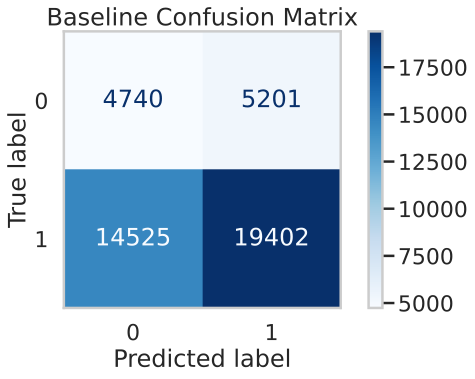

In [83]:
# confusion matrix for baseline
ConfusionMatrixDisplay.from_estimator(baseline_pl, X_test, y_test, cmap='Blues')
plt.title('Baseline Confusion Matrix')
plt.grid(False)
plt.show()

**Step 7: Final Model**

- engineered features: exclamation_count, word_count, sentiment, is_modifier, steps_per_ingredient
- also adding TF-IDF on review text
- trying 4 different algorithms, then tuning the best one with GridSearchCV

In [90]:
# define the numerical features for the final model
# baseline features + our 5 engineered features
num_final = ['n_steps', 'n_ingredients', 'minutes', 'calories',
             'review_length', 'exclamation_count', 'word_count',
             'sentiment', 'is_modifier', 'steps_per_ingredient']

In [86]:
# preprocessor for models that can handle negative values (LR, RF, SVC)
# StandardScaler centers and scales features to mean=0, std=1
preproc = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_final),
    ('text', TfidfVectorizer(max_features=5000, ngram_range=(1, 2)), 'review'),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), ['meal_type']),
])

# separate preprocessor for Naive Bayes  (NON-NEGATIVE inputs)
# so we use MinMaxScaler (scales to 0-1 range) instead of StandardScaler
preproc_nb = ColumnTransformer(transformers=[
    ('num', MinMaxScaler(), num_final),
    ('text', TfidfVectorizer(max_features=5000, ngram_range=(1, 2)), 'review'),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), ['meal_type']),
])

**Model 1 Logistic Regression**

In [87]:
# MODEL 1: Logistic Regression
#  good with sparse TF-IDF well
lr_pl = make_pipeline(preproc, LogisticRegression(max_iter=1000))
lr_scores = cross_val_score(lr_pl, X_train, y_train, cv=5, scoring='f1', n_jobs=-1)
print(f'mean F1 = {lr_scores.mean():.4f}  (std = {lr_scores.std():.4f})')

mean F1 = 0.9115  (std = 0.0013)


**Model 2 RandomForestClassifier**

In [89]:
# MODEL 2: Random Forest
# can capture non-linear patterns and feature interactions
rf_pl = make_pipeline(preproc, RandomForestClassifier(n_estimators=100, max_depth=20, random_state=42))
rf_scores = cross_val_score(rf_pl, X_train, y_train, cv=5, scoring='f1', n_jobs=-1)
print(f'mean F1 = {rf_scores.mean():.4f}  (std = {rf_scores.std():.4f})')

mean F1 = 0.8829  (std = 0.0006)


**Model 3: LinearSVC**

In [91]:
# MODEL 3: Linear SVC 
# max-margin linear classifier
svc_pl = make_pipeline(preproc, LinearSVC(max_iter=2000))
svc_scores = cross_val_score(svc_pl, X_train, y_train, cv=5, scoring='f1', n_jobs=-1)
print(f'mean F1 = {svc_scores.mean():.4f}  (std = {svc_scores.std():.4f})')

mean F1 = 0.9105  (std = 0.0011)


**Model 4: MultiNomialNB**

In [93]:
# MODEL 4: Multinomial Naive Bayes
# classic NLP classifier, models word frequency distributions directly
# uses preproc_nb with MinMaxScaler since NB needs non-negative features
nb_pl = make_pipeline(preproc_nb, MultinomialNB())
nb_scores = cross_val_score(nb_pl, X_train, y_train, cv=5, scoring='f1', n_jobs=-1)
print(f'mean F1 = {nb_scores.mean():.4f}  (std = {nb_scores.std():.4f})')

mean F1 = 0.9013  (std = 0.0008)


**Order each model by their f1 score (best to worst)**
- Logistic Regression Model mean F1 = 0.9115
- Linear SVC mean F1 = 0.9105
- Multinomial Naive Bayes mean F1 0.9013
- Random Forest Classification mean F1 0.8829

**Perform Hyperparameter Tuning**

Hyperparameter tuning

    tuning LogisticRegression (best from above)
    C: regularization strength (0.1, 0.5, 1.0)
    max_features: TF-IDF vocab size (3000, 5000)
    ngram_range: unigrams vs unigrams+bigrams


In [94]:
# HYPERPARAMETER TUNING for LR
# rebuild a fresh pipeline so GridSearchCV can vary the TF-IDF params
preproc_gs = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_final),
    ('text', TfidfVectorizer(max_features=5000), 'review'),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), ['meal_type']),
])

final_pl = make_pipeline(preproc_gs, LogisticRegression(max_iter=1000))

# search over these hyperparameters:
# C: regularization strength (lower = more regularization, prevents overfitting to rare words)
# max_features: how many TF-IDF words to keep
# ngram_range: unigrams only, or unigrams + bigrams (bigrams catch phrases like 'not good')
params = {
    'columntransformer__text__max_features': [3000, 5000],
    'columntransformer__text__ngram_range': [(1, 1), (1, 2)],
    'logisticregression__C': [0.1, 0.5, 1.0],
}

# 5-fold cross validation, optimize for F1
gs = GridSearchCV(final_pl, param_grid=params, cv=5, scoring='f1', n_jobs=-1)
gs.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('columntransformer',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['n_steps',
                                                                          'n_ingredients',
                                                                          'minutes',
                                                                          'calories',
                                                                          'review_length',
                                                                          'exclamation_count',
                                                                          'word_count',
                                                                          'sentiment',
                                                                          'is_modifier',
                                                                          'steps_per_ingredient']),
                                                                        ('text',
                                                                         TfidfVectorizer(max_features=5000),
                                                                         'review'),
                                                                        ('cat',
                                                                         OneHotEncoder(drop='first',
                                                                                       handle_unknown='ignore'),
                                                                         ['meal_type'])])),
                                       ('logisticregression',
                                        LogisticRegression(max_iter=1000))]),
             n_jobs=-1,
             param_grid={'columntransformer__text__max_features': [3000, 5000],
                         'columntransformer__text__ngram_range': [(1, 1),
                                                                  (1, 2)],
                         'logisticregression__C': [0.1, 0.5, 1.0]},
             scoring='f1')

In [95]:
# what hyperparameters worked best?
print('Best params:', gs.best_params_)
print(f'Best CV F1: {gs.best_score_:.4f}')

Best params: {'columntransformer__text__max_features': 5000, 'columntransformer__text__ngram_range': (1, 2), 'logisticregression__C': 0.5}
Best CV F1: 0.9117


In [96]:
# evaluate the tuned model on the held-out test set
final_pred = gs.predict(X_test)
print(classification_report(y_test, final_pred))
print(f'F1: {f1_score(y_test, final_pred):.4f}')

              precision    recall  f1-score   support

           0       0.77      0.53      0.63      9941
           1       0.87      0.96      0.91     33927

    accuracy                           0.86     43868
   macro avg       0.82      0.74      0.77     43868
weighted avg       0.85      0.86      0.85     43868

F1: 0.9124


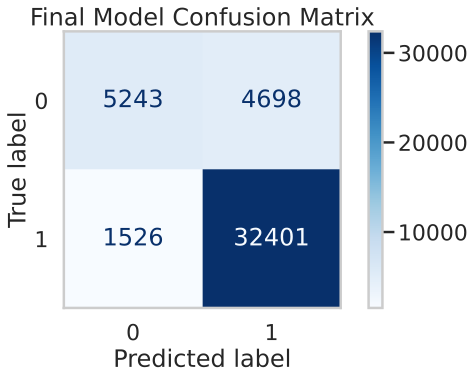

In [97]:
# confusion matrix for final model 
ConfusionMatrixDisplay.from_estimator(gs, X_test, y_test, cmap='Blues')
plt.title('Final Model Confusion Matrix')
plt.grid(False)
plt.show()

In [98]:
# side by side comparison: how much did we improve?
print(f'Baseline F1:  {f1_score(y_test, baseline_pred):.4f}')
print(f'Final F1:     {f1_score(y_test, final_pred):.4f}')
print(f'Baseline Acc: {accuracy_score(y_test, baseline_pred):.4f}')
print(f'Final Acc:    {accuracy_score(y_test, final_pred):.4f}')

Baseline F1:  0.6630
Final F1:     0.9124
Baseline Acc: 0.5503
Final Acc:    0.8581


**Using the hyperparameter tuning the f1 score improved by 24.94% and the accuracy improved by 30.78%**

**Step 8: Perform Fairness Analysis**

In [99]:
# what does the ingredient distribution look like in our test set?
X_test['n_ingredients'].describe().round(0).astype(int)

count    43868
mean         9
std          4
min          1
25%          6
50%          9
75%         11
max         32
Name: n_ingredients, dtype: int64

groups: simple recipes (n_ingredients ≤ median) vs complex (> median)
metric: precision
H0: precision is the same for both groups
H1: precision differs
α = 0.05

In [100]:
from sklearn.metrics import precision_score

# split test set into simple vs complex recipes based on median ingredient count
med_ingredients = X_test['n_ingredients'].median()
is_complex = (X_test['n_ingredients'] > med_ingredients).values

# compute precision for each group
prec_simple = precision_score(y_test[~is_complex], final_pred[~is_complex])
prec_complex = precision_score(y_test[is_complex], final_pred[is_complex])
observed_diff = abs(prec_simple - prec_complex)

print(f'Precision (simple): {prec_simple:.4f}')
print(f'Precision (complex): {prec_complex:.4f}')
print(f'Observed diff: {observed_diff:.4f}')

Precision (simple): 0.8746
Precision (complex): 0.8716
Observed diff: 0.0030


In [101]:
# permutation test for fairness
# shuffle which predictions belong to which group (simple vs complex)
n_reps = 1000
perm_diffs = []
for _ in range(n_reps):
    shuffled = np.random.permutation(is_complex)
    p_s = precision_score(y_test[~shuffled], final_pred[~shuffled])
    p_c = precision_score(y_test[shuffled], final_pred[shuffled])
    perm_diffs.append(abs(p_s - p_c))

p_value = np.mean(np.array(perm_diffs) >= observed_diff)
print(f'p-value: {p_value}')

p-value: 0.405


In [102]:
# plot the fairness permutation test
fig = px.histogram(pd.DataFrame({'Abs Difference in Precision': perm_diffs}),
                   x='Abs Difference in Precision', nbins=50,
                   title='Fairness Permutation Test: Simple vs Complex Recipes',
                   histnorm='probability')
fig.add_vline(x=observed_diff, line_color='red', line_width=2, opacity=1)
fig.show()

The permutation test produced a p-value greater than 0.05, meaning that we fail to reject the null hypothesis that the model has equal precision across simple and complex recipes. This suggests there is no statistical evidence that the model behaves differently between these two groups. 